# 02 Classical t-test baseline

Owner: Ma Tianjiao (B1, B3).

The t-test and CLT interval as the independence-based baseline, and a check of each assumption.

**Question.** Is the mean daily excess return of the pre-registered SMA5/SMA20 crossover rule over buy-and-hold different from zero?

- $d_t = r^{\text{rule}}_t - r_t$ (daily log returns, analysis window 2019-01-01 to 2025-12-31)
- $H_0: \mu_d = 0$ vs $H_1: \mu_d \neq 0$, two-sided, $\alpha = 0.05$

**What the t-test assumes.**
1. **Independence** — $d_t$ are independent across days.
2. **Identical distribution** — every $d_t$ has the same distribution (in particular the same variance).
3. **Finite variance** — so the CLT applies and $\bar d$ is approximately normal for large $n$.

Under these, $SE(\bar d) = s/\sqrt n$ and $t = \bar d / SE$ follows $t_{n-1}$ (≈ $N(0,1)$ for $n = 2{,}557$).
This notebook treats the t-test as the **independence-based baseline** (Prof. Qiu's second comment) and checks each assumption against the data.

## 0 · Setup

In [1]:
import sys
from pathlib import Path

# Run from either the repo root or notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from src import config
from src.data import load_daily
from src.strategy import build_series

FIG_DIR = config.FIG_DIR
TAB_DIR = config.TAB_DIR
FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR.mkdir(parents=True, exist_ok=True)

# Two fixed colours: blue = t-test, orange = block bootstrap
C_T, C_BOOT, C_GREY = "#2a78d6", "#eb6834", "#8a8a85"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "font.size": 10,
})
pd.options.display.float_format = "{:.6g}".format

rng = np.random.default_rng(config.SEED)

from statsmodels.tsa.stattools import acf
from statsmodels.stats.diagnostic import acorr_ljungbox
from src.classical import (t_test_mean, annualize, result_row,
                           variance_factor, sample_acf)

**Config.** Pre-registered values come from `src/config.py`. The lag choices below are fixed in the task pack (ACF lags 1–20, Ljung–Box at lag 10, 90-day rolling window). 

In [2]:
LEVEL = 1 - config.ALPHA          # 0.95
BLOCK_LEN = config.BLOCK_LENGTH    # 14, used as the lag window for the variance factor
SEED = config.SEED
ACF_LAGS = 20
LB_LAG = 10
ROLL_WIN = 90
DAYS_PER_YEAR = 365

## 1 · Data

Read through the shared modules only — no returns are recomputed here.

In [3]:
series = build_series(load_daily())
d = series["d"]
n = len(d)
print(f"n = {n:,}   window = {d.index.min().date()} to {d.index.max().date()}")
print(f"share of days with d == 0 (in market): {(d == 0).mean():.1%}")

n = 2,557   window = 2019-01-01 to 2025-12-31
share of days with d == 0 (in market): 55.4%


## 2 · Full-sample t-test

In [4]:
res = t_test_mean(d, LEVEL)
res_ann = annualize(res, DAYS_PER_YEAR)

full = pd.DataFrame([result_row("daily", res), result_row("annualised (x365)", res_ann)])
full.index.name = "scale"
full.to_csv(TAB_DIR / "02_t_test_full_sample.csv")
full

,n,mean,se,t,p,t_lo,t_hi,clt_lo,clt_hi
scale,,,,,,,,,
daily,2557,-0.000207795,0.00047466,-0.437775,0.661586,-0.00113855,0.000722964,-0.00113811,0.000722523
annualised (x365),2557,-0.075845,0.173251,-0.437775,0.661586,-0.415572,0.263882,-0.415411,0.263721


Check against the trial run in the task pack (10/21 pull). Small differences are fine; large ones mean something upstream changed.

In [5]:
REF = {"n": 2557, "mean": -0.00021, "se": 0.00048, "t": -0.44, "p": 0.66}
pd.DataFrame({"this run": [res[k] for k in REF], "trial run": list(REF.values())}, index=list(REF))

,this run,trial run
n,2557,2557
mean,-0.000207795,-0.00021
se,0.00047466,0.00048
t,-0.437775,-0.44
p,0.661586,0.66


<!-- DRAFT (AI-assisted): check every number, rewrite in your own words, then delete this line -->
**Interpretation.** The rule's mean daily excess return is $\bar d = -0.00021$, about $-7.6\%$ a year in log terms, with $SE = 0.00047$.
The t statistic is $-0.44$ with $p = 0.66$, and the 95% CI $[-0.00114,\ 0.00072]$ (roughly $-42\%$ to $+26\%$ a year) comfortably contains 0.
So under the t-test's assumptions we cannot reject $H_0$: the data are consistent with the rule doing exactly as well as buy-and-hold.
This is a statement about statistical evidence, not about profit: a negative point estimate with an interval this wide means seven years of data cannot tell the rule apart from buy-and-hold in either direction.

## 3 · Checking the assumptions one by one

### 3a · Independence — ACF and Ljung–Box

If $d_t$ were independent, the sample autocorrelations would sit inside the band $\pm 1.96/\sqrt n$ and Ljung–Box would not reject.
We look at $d$ (linear dependence, which affects $SE(\bar d)$) and $|d|$ (volatility clustering).
The numbers match notebook 01 (`01_ljung_box.csv`); they are recomputed here so this notebook runs on its own.

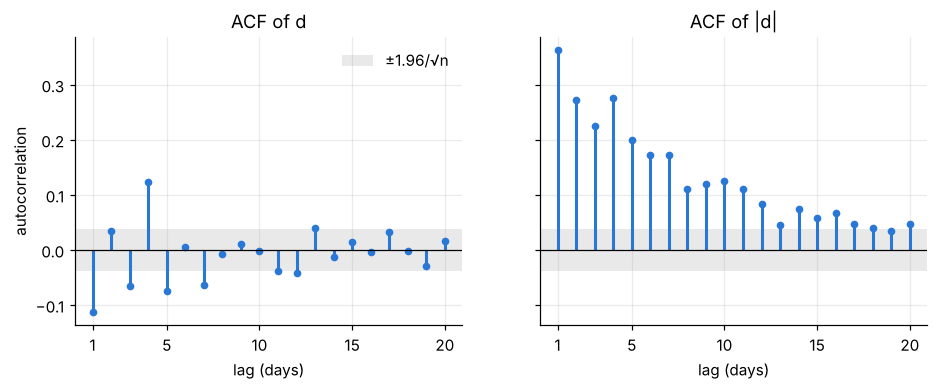

rho_1(d) = -0.113    rho_1(|d|) = 0.362    band = ±0.039


In [6]:
acf_d = acf(d, nlags=ACF_LAGS, fft=False)[1:]
acf_abs = acf(d.abs(), nlags=ACF_LAGS, fft=False)[1:]
band = 1.96 / np.sqrt(n)
lags = np.arange(1, ACF_LAGS + 1)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, vals, title in [(axes[0], acf_d, "ACF of d"), (axes[1], acf_abs, "ACF of |d|")]:
    ax.vlines(lags, 0, vals, color=C_T, lw=2)
    ax.plot(lags, vals, "o", color=C_T, ms=4)
    ax.axhspan(-band, band, color=C_GREY, alpha=0.18, lw=0, label="±1.96/√n")
    ax.axhline(0, color="black", lw=0.8)
    ax.set_title(title)
    ax.set_xlabel("lag (days)")
    ax.set_xticks([1, 5, 10, 15, 20])
axes[0].set_ylabel("autocorrelation")
axes[0].legend(loc="upper right", frameon=False)
fig.savefig(FIG_DIR / "02_acf_d.png")
plt.show()

print(f"rho_1(d) = {acf_d[0]:.3f}    rho_1(|d|) = {acf_abs[0]:.3f}    band = ±{band:.3f}")

In [7]:
lb = pd.concat({
    "d": acorr_ljungbox(d, lags=[LB_LAG]),
    "|d|": acorr_ljungbox(d.abs(), lags=[LB_LAG]),
    "d^2": acorr_ljungbox(d ** 2, lags=[LB_LAG]),
}).droplevel(1)
lb.index.name = "series"
lb.columns = ["Q", "p"]
lb.to_csv(TAB_DIR / "02_ljung_box.csv")
lb

,Q,p
series,,
d,111.046,3.28249e-19
|d|,1213.5,1.76416e-254
d^2,51.5947,1.35615e-07


<!-- DRAFT (AI-assisted): check every number, rewrite in your own words, then delete this line -->
**Interpretation.** Independence does not hold. $\rho_1(d) = -0.11$ is about three times the $\pm 0.039$ band, and Ljung–Box at lag 10 rejects strongly for $d$ ($Q = 111$, $p < 0.001$).
Dependence in $|d|$ is even stronger and lasts longer ($\rho_1 = 0.36$, still above the band at lag 20; $Q = 1{,}214$): big moves come in clusters.
So $d$ shows both kinds of dependence: linear (in $d$ itself) and volatility clustering (in $|d|$). Only the first enters $\operatorname{Var}(\bar d)$ directly — see section 4.

### 3b · Identical distribution — 90-day rolling standard deviation

If every $d_t$ had the same variance, the rolling SD would wander around one flat level. Long stretches far above or below it are volatility clustering.

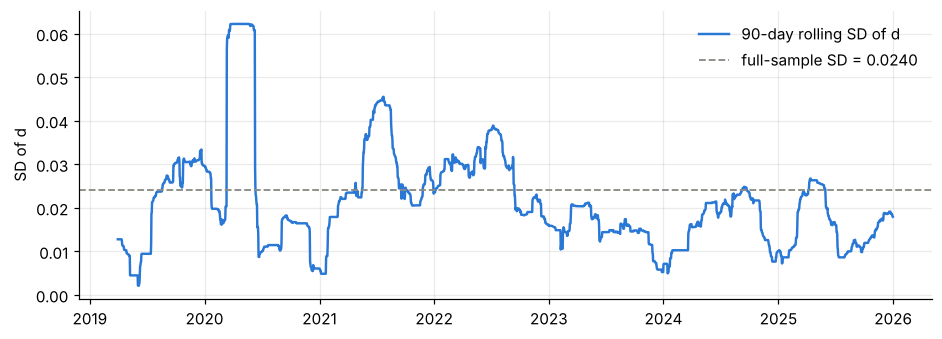

rolling SD range: 0.0021 to 0.0622  (ratio 29.5x)


,n,mean,sd
year,,,
2019,365,-0.000333904,0.0224145
2020,366,0.000479562,0.0324421
2021,365,-0.000384823,0.0300249
2022,365,0.000729769,0.0272996
2023,365,-0.000997977,0.0146138
2024,366,-0.000846312,0.0177027
2025,365,-0.000101011,0.0176221


In [8]:
roll_sd = d.rolling(ROLL_WIN).std()
sd_full = d.std(ddof=1)

fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(roll_sd.index, roll_sd, color=C_T, lw=1.6, label=f"{ROLL_WIN}-day rolling SD of d")
ax.axhline(sd_full, color=C_GREY, lw=1.2, ls="--", label=f"full-sample SD = {sd_full:.4f}")
ax.set_ylabel("SD of d")
ax.legend(frameon=False, loc="upper right")
fig.savefig(FIG_DIR / "02_rolling_sd_90d.png")
plt.show()

yearly = d.groupby(d.index.year).agg(n="size", mean="mean", sd="std")
yearly.index.name = "year"
yearly.to_csv(TAB_DIR / "02_sd_by_year.csv")
print(f"rolling SD range: {roll_sd.min():.4f} to {roll_sd.max():.4f}  (ratio {roll_sd.max() / roll_sd.min():.1f}x)")
yearly

<!-- DRAFT (AI-assisted): check every number, rewrite in your own words, then delete this line -->
**Interpretation.** The variance of $d$ is far from constant: the 90-day rolling SD runs from about 0.002 to 0.062, a factor of roughly 30.
Part of this is market volatility (yearly SD about 0.027–0.032 in 2020–2022 versus 0.015–0.018 in 2023–2025).
Part is mechanical: when the rule stays invested for most of a window, $d$ is exactly 0 on those days and the rolling SD collapses (mid-2019, late 2020, end of 2023).
The flat plateau at 0.062 from March to June 2020 is one day, 12 March 2020, sitting inside every 90-day window of that period (see 3d).
So the identical-distribution assumption does not hold either.

### 3c · Tails — skewness, kurtosis and how fast the CLT kicks in

Heavy tails do not break the t-test as long as the variance is finite, but they slow down the CLT.
For a mean of $n$ i.i.d. draws, skewness shrinks like $\gamma_1/\sqrt n$ and excess kurtosis like $\kappa/n$.
So we can ask: at our $n$, how far from normal is $\bar d$ still expected to be?

In [9]:
skew = stats.skew(d, bias=False)
exkurt = stats.kurtosis(d, fisher=True, bias=False)
print(f"skewness = {skew:.2f}   excess kurtosis = {exkurt:.1f}   (normal: 0 and 0)")

sizes = [30, 100, 365, 731, n]
clt = pd.DataFrame({
    "n": sizes,
    "skewness of d_bar": [skew / np.sqrt(m) for m in sizes],
    "excess kurtosis of d_bar": [exkurt / m for m in sizes],
}).set_index("n")
clt.to_csv(TAB_DIR / "02_clt_speed.csv")
clt

skewness = 3.52   excess kurtosis = 83.0   (normal: 0 and 0)


,skewness of d_bar,excess kurtosis of d_bar
n,,
30,0.643295,2.76717
100,0.352347,0.83015
365,0.184427,0.227438
731,0.13032,0.113564
2557,0.0696796,0.0324658


A picture of the same idea: the distribution of the mean of $m$ days drawn at random (i.i.d.) from $d$, for a small and for our full $m$. A straight Q–Q line means the normal approximation is fine.

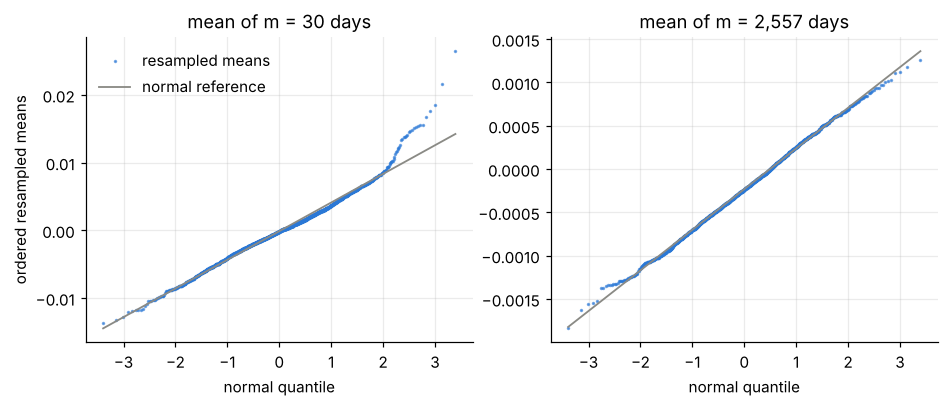

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, m in zip(axes, [30, n]):
    means = rng.choice(d.to_numpy(), size=(2_000, m), replace=True).mean(axis=1)
    (osm, osr), (slope, intercept, _) = stats.probplot(means, dist="norm")
    ax.plot(osm, osr, ".", color=C_T, ms=2.5, alpha=0.6, label="resampled means")
    ax.plot(osm, slope * osm + intercept, color=C_GREY, lw=1.2, label="normal reference")
    ax.set_title(f"mean of m = {m:,} days")
    ax.set_xlabel("normal quantile")
axes[0].set_ylabel("ordered resampled means")
axes[0].legend(frameon=False, loc="upper left")
fig.savefig(FIG_DIR / "02_clt_speed_qq.png")
plt.show()

<!-- DRAFT (AI-assisted): check every number, rewrite in your own words, then delete this line -->
**Interpretation.** $d$ is very heavy-tailed: excess kurtosis 83 (0 for a normal) and skewness 3.5.
Heavy tails do not break the t-test as long as the variance is finite, but they slow the CLT down.
For a mean of 30 days the implied excess kurtosis is still 2.8, and the left Q–Q plot bends away from the line in the upper tail.
At $n = 2{,}557$ the implied skewness of $\bar d$ is 0.07 and its excess kurtosis 0.03, and the right Q–Q plot is close to a straight line.
So at our sample size the normal approximation for $\bar d$ is fine; tails matter more for the shorter sub-periods in notebook 05 (365 and 731 days).

### 3d · Diagnostic: how much does a single day drive these numbers?

Notebook 01 shows that one day, 12 March 2020, dominates the right tail of $d$, and the rolling-SD plateau above points to the same day.
Here we take the next step and ask how much that day drives the **assumption checks** in this notebook: $\rho_1(d)$, the tail statistics and the variance factor in section 4.
This is a **diagnostic only** (not in the pre-registered plan): the main analysis keeps all 2,557 days.

In [11]:
crash = d.abs().idxmax()
print(series.loc[crash - pd.Timedelta(days=2):crash + pd.Timedelta(days=2), ["r", "s", "d"]])

x = d - d.mean()
lag1_products = x * x.shift(1)
next_day = crash + pd.Timedelta(days=1)
share = (lag1_products[crash] + lag1_products[next_day]) / lag1_products.sum()
print(f"\nshare of the lag-1 autocovariance from {crash.date()} and {next_day.date()}: {share:.0%}")


def describe(x):
    r = t_test_mean(x, LEVEL)
    return pd.Series({
        "n": len(x),
        "d_bar": x.mean(),
        "rho_1(d)": acf(x, nlags=1, fft=False)[1],
        "skewness": stats.skew(x, bias=False),
        "excess kurtosis": stats.kurtosis(x, bias=False),
        f"variance factor (Bartlett, K = {BLOCK_LEN})": variance_factor(x, BLOCK_LEN),
        "t": r["t"],
        "p": r["p"],
    })


influence = pd.DataFrame({"all days": describe(d), f"without {crash.date()}": describe(d.drop(crash))}).T
influence.to_csv(TAB_DIR / "02_single_day_influence.csv")
influence

                     r  s           d
date                                 
2020-03-10 -0.00446273  0  0.00446273
2020-03-11  0.00504895  0 -0.00504895
2020-03-12   -0.502607  0    0.502607
2020-03-13    0.150322  0   -0.150322
2020-03-14  -0.0756668  0   0.0756668

share of the lag-1 autocovariance from 2020-03-12 and 2020-03-13: 47%


,n,d_bar,rho_1(d),skewness,excess kurtosis,"variance factor (Bartlett, K = 14)",t,p
all days,2557,-0.000207795,-0.112745,3.52347,83.015,0.734756,-0.437775,0.661586
without 2020-03-12,2556,-0.000404514,-0.0717279,-0.0739784,12.283,0.767046,-0.936059,0.349331


<!-- DRAFT (AI-assisted): check every number, rewrite in your own words, then delete this line -->
**Interpretation.** One day drives the extreme tail statistics. On 12 March 2020 BTC fell about 40% (log return $-0.50$) while the rule was out of the market, so $d = +0.50$.
Removing that single day cuts excess kurtosis from 83 to 12 and skewness from 3.5 to about 0.
It also moves $\rho_1(d)$ from $-0.11$ to $-0.07$: that day and the rebound on 13 March contribute 47% of the lag-1 autocovariance.
The variance factor used in section 4 hardly moves (0.73 to 0.77), and neither does the conclusion ($p = 0.35$).
So the negative autocorrelation is partly a COVID-crash effect, but the direction of the t-test's bias does not depend on it.

## 4 · Which assumption actually matters for the CI of the mean?

For a stationary series,

$$\operatorname{Var}(\bar d) \approx \frac{\sigma^2}{n}\Big(1 + 2\sum_{k \ge 1} \rho_k\Big),$$

where $\rho_k$ is the autocorrelation of $d$ itself. The t-test sets the bracket to 1.

- Volatility clustering lives in $|d|$, not in $\rho_k$ of $d$, so on its own it leaves the bracket at 1 in large samples.
- Linear autocorrelation of $d$ moves the bracket: negative $\rho_k$ → bracket < 1 → the t-test SE is **too large** (conservative); positive → too small.

Below we estimate the bracket from the data, with Bartlett weights $w_k = 1 - k/(K+1)$ up to $K$ = block length, plus unweighted sums for a few $K$ as a sanity check.

In [12]:
rho = sample_acf(d, ACF_LAGS)
rows = [("rho_1 only", 1 + 2 * rho[0])]
rows += [(f"Bartlett, K = {BLOCK_LEN}", variance_factor(d, BLOCK_LEN, bartlett=True))]
rows += [(f"unweighted, K = {K}", variance_factor(d, K, bartlett=False)) for K in (1, 5, 10, ACF_LAGS)]

vf = pd.DataFrame(rows, columns=["estimate", "factor"]).set_index("estimate")
vf["implied SE"] = res["se"] * np.sqrt(vf["factor"])
vf["implied SE / t-test SE"] = np.sqrt(vf["factor"])
vf.to_csv(TAB_DIR / "02_variance_factor.csv")
print(f"t-test SE = {res['se']:.6f}   (trial-run block bootstrap SE, l = 14: 0.00041)")
vf

t-test SE = 0.000475   (trial-run block bootstrap SE, l = 14: 0.00041)


,factor,implied SE,implied SE / t-test SE
estimate,,,
rho_1 only,0.77451,0.000417731,0.880062
"Bartlett, K = 14",0.734756,0.000406869,0.857179
"unweighted, K = 1",0.77451,0.000417731,0.880062
"unweighted, K = 5",0.808498,0.000426798,0.899165
"unweighted, K = 10",0.693261,0.000395213,0.832623
"unweighted, K = 20",0.647849,0.00038205,0.804891


<!-- DRAFT (AI-assisted): check every number, rewrite in your own words, then delete this line -->
**Interpretation.** For the CI of the mean, the assumption that matters is linear independence: autocorrelation of $d$ itself.
Volatility clustering and changing variance live mainly in $|d|$; in large samples they leave the bracket $1 + 2\sum\rho_k$ at 1, so on their own they do not bias the t-test SE.
Heavy tails only slow the CLT, which is not a problem at $n = 2{,}557$ (3c).
Our $\rho_1(d)$ is negative, so the bracket is below 1: 0.77 from $\rho_1$ alone and 0.73 with Bartlett weights up to lag 14.
The dependence-adjusted SE is therefore about 12–14% smaller than the t-test SE (about 0.00041–0.00042 instead of 0.00047), which matches the block-bootstrap SE in notebook 03 (about 0.00042).
This is why the bootstrap interval comes out *narrower* than the t interval; notebook 04 checks in simulation whether that direction is real.

## 5 · Summary table for notebook 03 / slides

In [13]:
summary = pd.DataFrame({
    "n": [res["n"]],
    "d_bar": [res["mean"]],
    "SE": [res["se"]],
    "t": [res["t"]],
    "p": [res["p"]],
    "95% CI (t)": [f"[{res['t_lo']:.5f}, {res['t_hi']:.5f}]"],
    "95% CI (CLT, 1.96)": [f"[{res['clt_lo']:.5f}, {res['clt_hi']:.5f}]"],
    "rho_1(d)": [acf_d[0]],
    "rho_1(|d|)": [acf_abs[0]],
    "excess kurtosis": [exkurt],
}, index=["t-test, full sample"])
summary.to_csv(TAB_DIR / "02_summary.csv")
summary.T

,"t-test, full sample"
n,2557
d_bar,-0.000207795
SE,0.00047466
t,-0.437775
p,0.661586
95% CI (t),"[-0.00114, 0.00072]"
"95% CI (CLT, 1.96)","[-0.00114, 0.00072]"
rho_1(d),-0.112745
rho_1(|d|),0.36245
excess kurtosis,83.015
